# 🦴 Bone Age from Hand X-Rays

### Sex-conditioned EfficientNetV2-S regression on the RSNA Pediatric Bone Age dataset

_Author: **Azizul Abedin Azmi** · [ORCID 0009-0003-5269-6900](https://orcid.org/0009-0003-5269-6900)_

When a child grows unusually fast or slowly, one of the first things a pediatrician orders is an X-ray of the left
hand. A radiologist compares the bones with an atlas and writes down a **bone age**. If it is far from the child's real
age, that can point to a hormone problem, early puberty or a growth disorder. The comparison is slow and different
readers often disagree by several months.

In this notebook I teach a CNN to do that reading. It looks at the X-ray, is told whether the child is a boy or a
girl, and predicts the bone age in months. I wanted it to be honest as well as accurate, so I hold out 1,425 images
it never sees during training and compare it with two models that never look at the image at all.

> **At a glance**
>
> - **Task:** regression, bone age in months from one hand X-ray + sex
> - **Metric:** mean absolute error (MAE) in months, overall and for boys and girls separately
> - **Model:** EfficientNetV2-S (ImageNet-21k) with a learned sex embedding, L1 loss, EMA, flip TTA
> - **Hardware:** the _same_ notebook runs on my **laptop RTX 4060 (8 GB)** and on a **Kaggle GPU**. Each run saves
>   its hardware, timings and scores, and section 13 puts the two side by side.

| Section | Content                                                                |
| ------- | ---------------------------------------------------------------------- |
| 1       | Setup, configuration, paths (local or Kaggle)                          |
| 2       | Data discovery / optional download                                     |
| 3       | Exploratory analysis of the targets (by sex) and images                |
| 4       | Preprocessing: polarity fix, pad-to-square, CLAHE, cache               |
| 5       | Stratified hold-out + 5-fold split, target normalisation               |
| 6       | Image-free baselines                                                   |
| 7       | Dataset & augmentation                                                 |
| 8       | Model: CNN image features + sex embedding                              |
| 9       | GPU preflight and training (AMP, EMA, cosine schedule)                 |
| 10      | Hold-out evaluation in months, by sex and by age band                  |
| 11      | Error analysis & Grad-CAM                                              |
| 12      | Kaggle test predictions, single-image inference, run record            |
| 13      | Hardware comparison: local RTX 4060 vs Kaggle, written into the README |


## 1. Setup, configuration and paths

Everything you might want to change is in the `CFG` class below. The defaults are what I use for the main run. Set
`QUICK_DEBUG = True` first if you just want to check that the whole notebook runs (it takes a few minutes).


In [1]:
import os, sys, glob, json, math, random, time, copy, re, platform, shutil, subprocess, warnings
T_START = time.time()
warnings.filterwarnings("ignore")

def _pip(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

try:
    import timm
except ImportError:
    _pip("timm"); import timm
try:
    import albumentations as A
except ImportError:
    _pip("albumentations"); import albumentations as A

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split, StratifiedKFold
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader

ON_KAGGLE = os.path.isdir("/kaggle/working")
ON_WINDOWS = platform.system() == "Windows"
print("torch", torch.__version__, "| timm", timm.__version__, "| albumentations", A.__version__)
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
sns.set_theme(style="whitegrid", context="notebook")

# torch was reinstalled while this kernel was running: the kernel still has the old version in memory, but
# DataLoader workers (fresh processes on Windows) load the new one -> crashes such as "IndexError: list index out of range"
from importlib.metadata import version as _pkg_version
if _pkg_version("torch").split("+")[0] != torch.__version__.split("+")[0]:
    raise RuntimeError(f"This kernel runs torch {torch.__version__}, but torch {_pkg_version('torch')} is installed. "
                       "Restart the kernel (VS Code: 'Restart' in the notebook toolbar), then run all cells again.")

# An NVIDIA GPU is present but this PyTorch can't use it (typical on Windows after a plain `pip install torch`)
if not torch.cuda.is_available() and shutil.which("nvidia-smi"):
    print("\n" + "⚠️ " * 20)
    print("An NVIDIA GPU was found, but this PyTorch build is CPU-only:", torch.__version__)
    print("Training on the CPU would take days. Fix it in this kernel's environment, then restart the kernel:")
    print(f'  "{sys.executable}" -m pip install --force-reinstall torch torchvision '
          "--index-url https://download.pytorch.org/whl/cu128")
    print("⚠️ " * 20)

torch 2.11.0+cu128 | timm 1.0.31 | albumentations 2.0.8
CUDA: True NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
class CFG:
    SEED          = 42
    # Backbone (any timm model name). Alternatives:
    #   "resnet50.tv2_in1k"                 -> classic ResNet-50 (torchvision IMAGENET1K_V2) reference
    #   "convnext_small.fb_in22k_ft_in1k"   -> strong, a bit slower
    #   "tf_efficientnetv2_m.in21k_ft_in1k" -> bigger; best with IMG_SIZE 576-640
    BACKBONE      = "tf_efficientnetv2_s.in21k_ft_in1k"
    PRETRAINED    = True
    IMG_SIZE      = 512          # network input
    CACHE_SIZE    = 576          # preprocessed square images are cached at this size
    USE_CLAHE     = True
    BATCH_SIZE    = 16           # halved automatically by the GPU preflight if it does not fit
    EPOCHS        = 20
    LR            = 2e-4         # backbone LR; head uses HEAD_LR_MULT x LR
    HEAD_LR_MULT  = 5.0
    WEIGHT_DECAY  = 1e-2
    WARMUP_EPOCHS = 1
    EMA_DECAY     = 0.998
    LOSS          = "l1"         # "l1" (optimises MAE directly) or "huber"
    N_FOLDS       = 5
    TRAIN_FOLDS   = [0]          # [0, 1, 2, 3, 4] for the full 5-model ensemble (best score)
    HOLDOUT_SIZE  = 1425         # same size as the official RSNA validation set
    TTA           = True         # average prediction with horizontal flip
    CHANNELS_LAST = False        # NHWC layout: ~5x SLOWER on an RTX 4060 laptop with torch 2.11/cuDNN 9.19, keep off
    NUM_WORKERS   = 4 if ON_WINDOWS else min(8, os.cpu_count() or 2)
    AUTO_DOWNLOAD = True         # local only: download the dataset with the kaggle CLI if missing
    RUN_TAG       = None         # None -> "<local|kaggle>-<gpu name>", e.g. "local-rtx-4060-laptop-gpu"
    QUICK_DEBUG   = False        # True -> tiny subset, 2 epochs: smoke test the pipeline
    DEVICE        = "cuda" if torch.cuda.is_available() else "cpu"

# Overrides without editing the notebook, e.g.  BONEAGE_CFG='{"EPOCHS": 2, "TRAIN_FOLDS": [0]}'
for k, v in json.loads(os.environ.get("BONEAGE_CFG", "{}")).items():
    setattr(CFG, k, v)
if CFG.QUICK_DEBUG:
    CFG.EPOCHS, CFG.BATCH_SIZE, CFG.IMG_SIZE, CFG.CACHE_SIZE = 2, 8, 256, 288

def notebook_dir():
    # The folder this .ipynb lives in, whatever the current working directory is.
    if ON_KAGGLE:
        return "/kaggle/working"
    vsc = globals().get("__vsc_ipynb_file__")                  # set by VS Code
    if vsc:
        return os.path.dirname(os.path.abspath(vsc))
    jpy = os.environ.get("JPY_SESSION_NAME", "")                # set by JupyterLab / Notebook 7
    if jpy.endswith(".ipynb") and os.path.isfile(jpy):
        return os.path.dirname(os.path.abspath(jpy))
    return os.getcwd()                                          # Jupyter starts kernels in the notebook's folder

NOTEBOOK_DIR = os.environ.get("BONEAGE_NOTEBOOK_DIR", notebook_dir())
WORK_DIR   = os.environ.get("BONEAGE_WORK",   "/kaggle/working" if ON_KAGGLE else os.path.join(NOTEBOOK_DIR, "work"))
ASSETS_DIR = os.environ.get("BONEAGE_ASSETS", "/kaggle/working/assets" if ON_KAGGLE else os.path.join(NOTEBOOK_DIR, "..", "assets"))
CACHE_ROOT = os.environ.get("BONEAGE_TMP",    "/tmp/boneage_cache" if ON_KAGGLE else os.path.join(WORK_DIR, "cache"))
MODEL_DIR, RUNS_DIR = os.path.join(WORK_DIR, "models"), os.path.join(WORK_DIR, "runs")
for d in [WORK_DIR, ASSETS_DIR, CACHE_ROOT, MODEL_DIR, RUNS_DIR]:
    os.makedirs(d, exist_ok=True)

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
if CFG.RUN_TAG is None:
    CFG.RUN_TAG = ("kaggle-" if ON_KAGGLE else "local-") + re.sub(r"[^a-z0-9]+", "-", gpu_name.lower().replace("nvidia", "")).strip("-")
print("notebook folder:", NOTEBOOK_DIR)
print("run tag:", CFG.RUN_TAG, "| work:", os.path.abspath(WORK_DIR), "| figures:", os.path.abspath(ASSETS_DIR))

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
seed_everything(CFG.SEED)

TIMES = {}                      # wall-clock seconds per stage, saved in the run record
def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def savefig(name):
    plt.savefig(os.path.join(ASSETS_DIR, name), dpi=150, bbox_inches="tight")

notebook folder: d:\ML\Bone Age From Hand X-Rays\Notebook
run tag: local-geforce-rtx-4060-laptop-gpu | work: d:\ML\Bone Age From Hand X-Rays\Notebook\work | figures: d:\ML\Bone Age From Hand X-Rays\assets


## 2. Finding the data (and downloading it only if it's missing)

I run this notebook in two places, so it **looks for the dataset first** and only downloads as a last resort:

| Where                      | Where the data is                                                         | What happens                                                  |
| -------------------------- | ------------------------------------------------------------------------- | ------------------------------------------------------------- |
| **Kaggle**                 | _Add Input_ → `RSNA Bone Age`, mounted under `/kaggle/input` (`../input`) | found right away, nothing downloaded                          |
| **My laptop**              | `Notebook/data/rsna-bone-age/`, or wherever `BONEAGE_DATA` points         | found right away                                              |
| **Anywhere, data missing** | –                                                                         | downloaded once (≈ 10 GB) into `Notebook/data/rsna-bone-age/` |

The folder layout doesn't matter: the search goes into every sub-folder (and follows symlinks) until it finds
`boneage-training-dataset.csv`.


In [3]:
import shutil
DATASET  = "kmader/rsna-bone-age"
CSV_NAME = "boneage-training-dataset.csv"
# Downloads go into the notebook's own folder: Notebook/data/rsna-bone-age/
DOWNLOAD_DIR = os.environ.get("BONEAGE_DATA") or os.path.join(NOTEBOOK_DIR, "data", "rsna-bone-age")
SEARCH_ROOTS = [os.environ.get("BONEAGE_DATA", ""),
                "/kaggle/input", "../input",                          # Kaggle: attached dataset
                os.path.join(NOTEBOOK_DIR, "data"), NOTEBOOK_DIR,     # next to this notebook
                os.path.join(NOTEBOOK_DIR, "..", "data"), "./data", "/content/data"]
SKIP_DIRS = {"work", "cache", "models", "runs", ".venv", "venv", ".git", "__pycache__", ".ipynb_checkpoints"}

def find_dataset():
    for root in dict.fromkeys(os.path.abspath(r) for r in SEARCH_ROOTS if r):
        if not os.path.isdir(root):
            continue
        for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
            if CSV_NAME in filenames:
                return os.path.join(dirpath, CSV_NAME)
            dirnames[:] = [d for d in dirnames if not d.startswith(".") and d not in SKIP_DIRS]
    return None

TRAIN_CSV = find_dataset()
if TRAIN_CSV:
    print(f"✅ Found the dataset in {os.path.abspath(os.path.dirname(TRAIN_CSV))}")
else:
    print("❌ Dataset not found in any of these folders:")
    for r in filter(None, SEARCH_ROOTS):
        print(f"   {os.path.abspath(r)}{'' if os.path.isdir(r) else '  (does not exist)'}")
    print("   -> the next cell will download it" if CFG.AUTO_DOWNLOAD else "   -> AUTO_DOWNLOAD is off")

✅ Found the dataset in d:\ML\Bone Age From Hand X-Rays\Notebook\data\rsna-bone-age


### 2.1 Download (skipped when the dataset was found)

- **Locally**, the dataset is downloaded **into the notebook's own folder**: `Notebook/data/rsna-bone-age/`, whatever the current working directory is. The `kaggle` CLI is tried first. It needs your API token in
  `~/.kaggle/kaggle.json` (_Kaggle → Settings → API → Create New Token_).
- **If the CLI is missing or fails**, `kagglehub` downloads into the same folder.
- **On Kaggle without the dataset attached** (Internet must be _On_), `kagglehub` uses Kaggle's cache, because
  `/kaggle/working` is saved as the notebook's output.
- The search above runs again afterwards, so the rest of the notebook doesn't care where the files ended up.


In [4]:
def kaggle_cli():
    exe = "kaggle.exe" if ON_WINDOWS else "kaggle"
    local = os.path.join(os.path.dirname(sys.executable), exe)        # the venv's own kaggle, if any
    return local if os.path.exists(local) else shutil.which("kaggle")

def download_dataset():
    if not ON_KAGGLE and kaggle_cli():
        os.makedirs(DOWNLOAD_DIR, exist_ok=True)
        print(f"⬇️  Downloading {DATASET} (≈ 10 GB) to {DOWNLOAD_DIR} with the kaggle CLI ...")
        if subprocess.run([kaggle_cli(), "datasets", "download", "-d", DATASET, "-p", DOWNLOAD_DIR, "--unzip"]).returncode == 0:
            return
        print("kaggle CLI failed (no API token?) -> trying kagglehub ...")
    try:
        import kagglehub
    except ImportError:
        _pip("kagglehub"); import kagglehub
    if ON_KAGGLE:   # /kaggle/working is saved as the notebook's output, so keep 10 GB of data out of it
        print(f"⬇️  Downloading {DATASET} with kagglehub (Kaggle cache) ...")
        SEARCH_ROOTS.insert(0, kagglehub.dataset_download(DATASET))
        return
    os.makedirs(DOWNLOAD_DIR, exist_ok=True)
    print(f"⬇️  Downloading {DATASET} (≈ 10 GB) to {DOWNLOAD_DIR} with kagglehub ...")
    try:
        path = kagglehub.dataset_download(DATASET, output_dir=DOWNLOAD_DIR)
    except TypeError:                           # older kagglehub without output_dir -> upgrade and retry
        _pip("kagglehub>=0.3.13")
        import importlib; importlib.reload(kagglehub)
        try:
            path = kagglehub.dataset_download(DATASET, output_dir=DOWNLOAD_DIR)
        except TypeError:
            path = kagglehub.dataset_download(DATASET)
            print(f"⚠️ this kagglehub version can't choose the folder; the data is in {path}")
    SEARCH_ROOTS.insert(0, path)

if TRAIN_CSV:
    print("Nothing to download: the dataset is already here.")
elif not CFG.AUTO_DOWNLOAD:
    raise FileNotFoundError("Dataset not found and AUTO_DOWNLOAD = False. Attach it on Kaggle (Add Input -> "
                            "'RSNA Bone Age') or put it in Notebook/data/rsna-bone-age/, or set BONEAGE_DATA.")
else:
    t0 = time.time()
    download_dataset()
    TRAIN_CSV = find_dataset()
    if TRAIN_CSV is None:
        raise FileNotFoundError(
            "Download finished but boneage-training-dataset.csv is still missing.\n"
            " - On Kaggle: click 'Add Input', search 'RSNA Bone Age' (kmader), or turn Internet On.\n"
            " - Locally: check ~/.kaggle/kaggle.json, or download the zip from "
            "https://www.kaggle.com/datasets/kmader/rsna-bone-age and unzip it into " + DOWNLOAD_DIR)
    TIMES["download_s"] = time.time() - t0
    print(f"✅ Downloaded in {TIMES['download_s'] / 60:.1f} min -> {os.path.dirname(TRAIN_CSV)}")

Nothing to download: the dataset is already here.


### 2.2 Loading the labels

`boneage-training-dataset.csv` has `id`, `boneage` (months) and `male`. The test CSV has `Case ID` and `Sex` (M/F),
with no bone age. I match every row to its PNG and drop any row whose image is missing.


In [5]:
DATA_ROOT = os.path.dirname(TRAIN_CSV)
def find_csv(name):
    for dirpath, _, filenames in os.walk(DATA_ROOT, followlinks=True):
        if name in filenames:
            return os.path.join(dirpath, name)
    return None

TEST_CSV = find_csv("boneage-test-dataset.csv")

all_png = [os.path.join(dp, f) for dp, _, fs in os.walk(DATA_ROOT, followlinks=True) for f in fs if f.lower().endswith(".png")]
def png_index(word):   # match on the path *inside* DATA_ROOT, so parent folder names don't matter
    return {int(os.path.splitext(os.path.basename(p))[0]): p for p in all_png
            if word in os.path.relpath(p, DATA_ROOT).lower()}
train_png, test_png = png_index("train"), png_index("test")

df = pd.read_csv(TRAIN_CSV)
df["male"] = df["male"].astype(str).str.lower().isin(["true", "1"]).astype(float)
df["path"] = df["id"].map(train_png)
print(f"{len(df):,} labelled rows, {df.path.notna().sum():,} with images on disk")
df = df.dropna(subset=["path"]).reset_index(drop=True)

if TEST_CSV:
    test_df = pd.read_csv(TEST_CSV)
    id_col  = [c for c in test_df.columns if "id" in c.lower()][0]
    sex_col = [c for c in test_df.columns if "sex" in c.lower() or "male" in c.lower()][0]
    test_df = test_df.rename(columns={id_col: "id"})
    test_df["male"] = test_df[sex_col].astype(str).str.upper().isin(["M", "TRUE", "1"]).astype(float)
    test_df["path"] = test_df["id"].map(test_png)
    test_df = test_df.dropna(subset=["path"]).reset_index(drop=True)
    print(f"{len(test_df):,} unlabelled Kaggle test images")
else:
    test_df = None

if CFG.QUICK_DEBUG:
    df = df.sample(min(600, len(df)), random_state=CFG.SEED).reset_index(drop=True)
df.head()

12,611 labelled rows, 12,611 with images on disk
200 unlabelled Kaggle test images


,id,boneage,male,path
0,1377,180,0.0,d:\ML\Bone Age From Hand X-Rays\Notebook\data\...
1,1378,12,0.0,d:\ML\Bone Age From Hand X-Rays\Notebook\data\...
2,1379,94,0.0,d:\ML\Bone Age From Hand X-Rays\Notebook\data\...
3,1380,120,1.0,d:\ML\Bone Age From Hand X-Rays\Notebook\data\...
4,1381,82,0.0,d:\ML\Bone Age From Hand X-Rays\Notebook\data\...


## 3. Looking at the data first

### 3.1 Bone age for boys and girls

Girls' skeletons mature earlier than boys', so the bone-age atlases have separate standards for each sex. Before
building anything I want to see how different the two distributions really are.


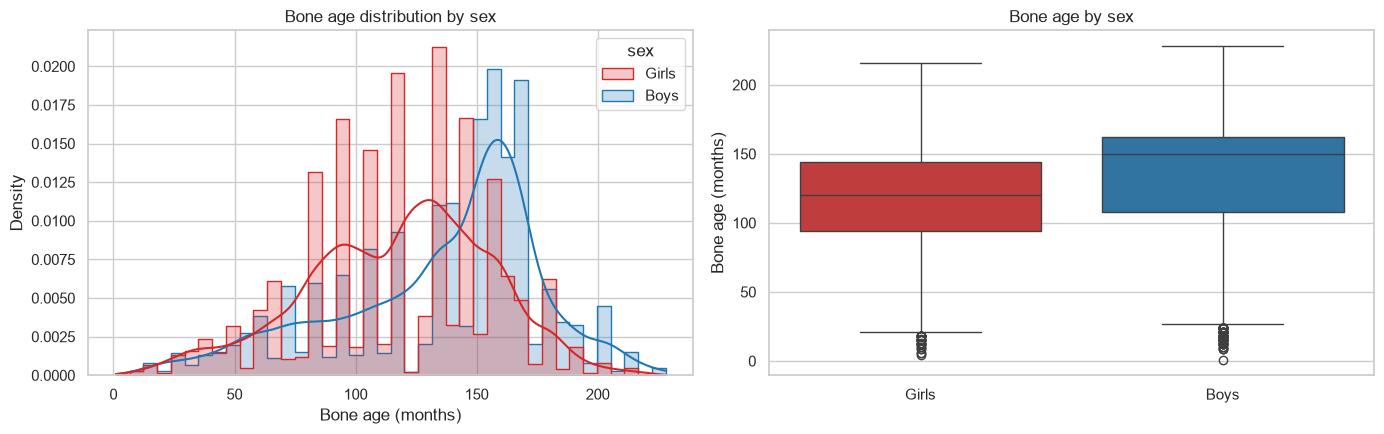

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
Boys,6833.0,135.3,42.1,1.0,108.0,150.0,162.0,228.0
Girls,5778.0,117.9,37.9,4.0,94.0,120.0,144.0,216.0
All,12611.0,127.3,41.2,1.0,96.0,132.0,156.0,228.0


In [6]:
PAL = {"Boys": "#1f77b4", "Girls": "#d62728"}
df["sex"] = np.where(df.male == 1, "Boys", "Girls")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df, x="boneage", hue="sex", bins=40, kde=True, element="step", stat="density",
             common_norm=False, ax=ax[0], palette=PAL)
ax[0].set(title="Bone age distribution by sex", xlabel="Bone age (months)")
sns.boxplot(df, x="sex", y="boneage", ax=ax[1], palette=PAL)
ax[1].set(title="Bone age by sex", ylabel="Bone age (months)", xlabel="")
plt.tight_layout(); savefig("boneage_distribution.png"); plt.show()

stats = df.groupby("sex").boneage.describe().round(1)
stats.loc["All"] = df.boneage.describe().round(1)
stats

### 3.2 What the images look like

The X-rays come in many sizes and shapes. That matters for the next step: if I squeeze them all into a square, the
hands get distorted.


width  521–3001  | height 640–2989
aspect ratio h/w: median 1.26, range 0.64–2.16


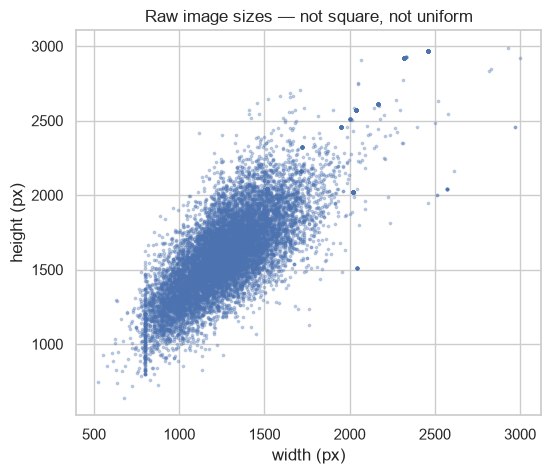

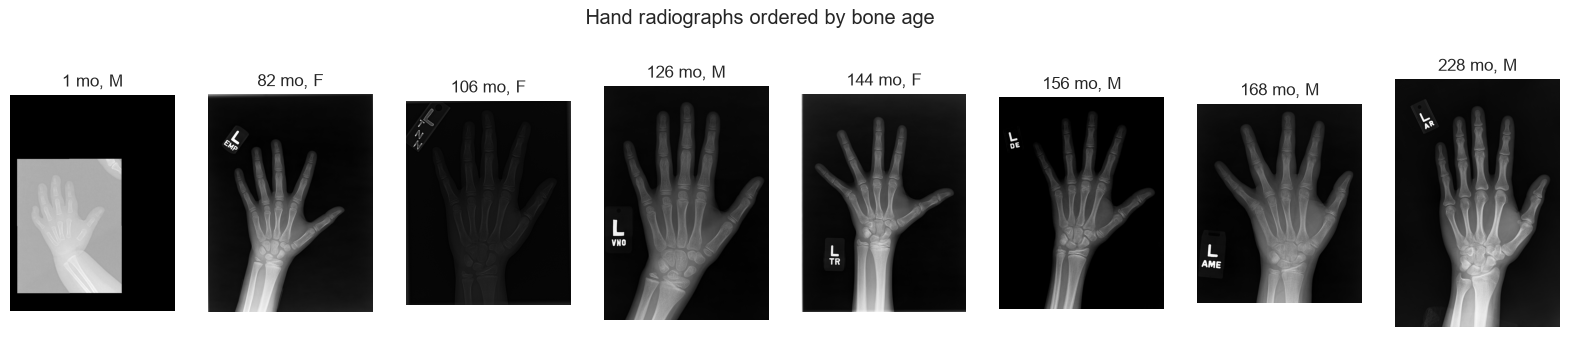

In [7]:
def img_size(p):
    with Image.open(p) as im:            # reads the header only
        return im.size                   # (width, height)
sizes = np.array([img_size(p) for p in df.path])
print(f"width  {sizes[:,0].min()}–{sizes[:,0].max()}  | height {sizes[:,1].min()}–{sizes[:,1].max()}")
print(f"aspect ratio h/w: median {np.median(sizes[:,1]/sizes[:,0]):.2f}, "
      f"range {np.min(sizes[:,1]/sizes[:,0]):.2f}–{np.max(sizes[:,1]/sizes[:,0]):.2f}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sizes[:, 0], sizes[:, 1], s=3, alpha=.3)
ax.set(xlabel="width (px)", ylabel="height (px)", title="Raw image sizes — not square, not uniform")
savefig("image_sizes.png"); plt.show()

ex = df.sort_values("boneage").iloc[np.linspace(0, len(df) - 1, 8).astype(int)]
fig, axes = plt.subplots(1, 8, figsize=(20, 4))
for a, (_, r) in zip(axes, ex.iterrows()):
    a.imshow(cv2.imread(r.path, cv2.IMREAD_GRAYSCALE), cmap="gray"); a.axis("off")
    a.set_title(f"{r.boneage:.0f} mo, {'M' if r.male else 'F'}")
plt.suptitle("Hand radiographs ordered by bone age"); savefig("output.png"); plt.show()

## 4. Preprocessing

Every X-ray goes through four steps:

1. **Fix inverted scans.** A few images are stored as negatives, with a white background. I flip those back.
2. **Pad to a square, then resize.** Resizing straight to a square would stretch or squash the hand, and the model
   needs real bone proportions. So I pad with black first and then resize.
3. **CLAHE contrast.** X-rays from different machines look quite different. Contrast-limited adaptive histogram
   equalisation evens that out.
4. **Cache.** The results are saved once as small PNGs, so later epochs don't decode the large originals again.

> 💡 **Why a separate `boneage_lib.py` file?** On Windows, DataLoader workers are _spawned_ rather than forked, and a
> spawned worker can't load a class that only exists in a notebook cell. The next cell writes the preprocessing
> function and the `Dataset` to a small file, so the same code works on my Windows laptop and on Kaggle's Linux.


In [8]:
%%writefile boneage_lib.py
# Written by the notebook. Importable helpers so DataLoader workers also work on Windows (spawn).
import cv2, numpy as np, torch
from torch.utils.data import Dataset

NORM_MEAN, NORM_STD = 0.449, 0.226   # ImageNet statistics of a grey image


def load_hand(path, size=512, clahe=True):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    b = max(4, min(h, w) // 20)
    border = np.concatenate([img[:b].ravel(), img[-b:].ravel(), img[:, :b].ravel(), img[:, -b:].ravel()])
    centre = img[h // 4: 3 * h // 4, w // 4: 3 * w // 4]
    if np.median(border) > 128 and np.median(border) > np.median(centre):  # negative polarity -> invert
        img = 255 - img
    s = max(h, w)                              # pad to a square first,
    pad = np.zeros((s, s), np.uint8)           # so the hand isn't squashed
    pad[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = img
    img = cv2.resize(pad, (size, size), interpolation=cv2.INTER_AREA)
    if clahe:
        img = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)
    return img


def cache_one(src, dst, size, clahe):
    import os
    if not os.path.exists(dst):
        cv2.imwrite(dst, load_hand(src, size, clahe))
    return dst


def to_tensor(img):
    img = (img.astype(np.float32) / 255.0 - NORM_MEAN) / NORM_STD
    return torch.from_numpy(img)[None]


class BoneAgeDataset(Dataset):
    def __init__(self, paths, male, target, tfm):
        self.paths, self.tfm = list(paths), tfm
        self.male = np.asarray(male, np.float32)
        self.target = np.asarray(target, np.float32)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.imread(self.paths[i], cv2.IMREAD_GRAYSCALE)
        img = self.tfm(image=img)["image"]
        return to_tensor(img), torch.tensor(self.male[i]), torch.tensor(self.target[i])

Overwriting boneage_lib.py


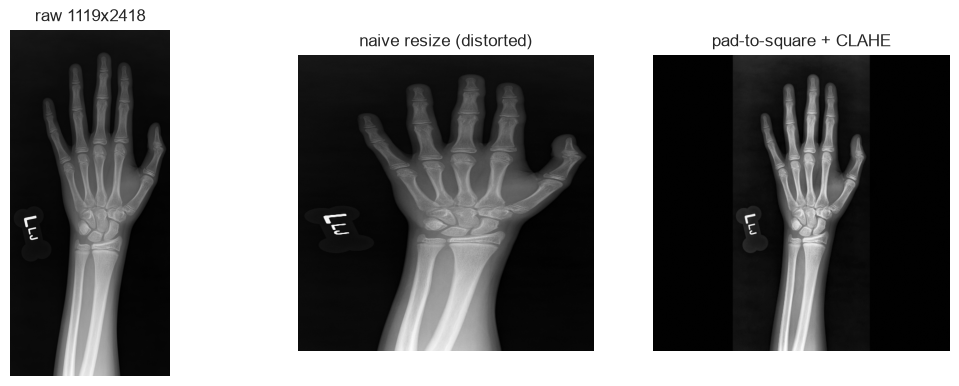

In [9]:
import importlib, boneage_lib
importlib.reload(boneage_lib)
from boneage_lib import load_hand, cache_one, to_tensor, BoneAgeDataset, NORM_MEAN, NORM_STD

r = df.iloc[int(np.argmax(sizes[:, 1] / sizes[:, 0]))]  # the most elongated image
raw = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
ax[0].imshow(raw, cmap="gray"); ax[0].set_title(f"raw {raw.shape[1]}x{raw.shape[0]}")
ax[1].imshow(cv2.resize(raw, (CFG.IMG_SIZE,) * 2), cmap="gray"); ax[1].set_title("naive resize (distorted)")
ax[2].imshow(load_hand(r.path, CFG.IMG_SIZE, CFG.USE_CLAHE), cmap="gray"); ax[2].set_title("pad-to-square + CLAHE")
[a.axis("off") for a in ax]; savefig("preprocessing.png"); plt.show()

In [10]:
CACHE_DIR = os.path.join(CACHE_ROOT, f"s{CFG.CACHE_SIZE}_clahe{int(CFG.USE_CLAHE)}")
os.makedirs(CACHE_DIR, exist_ok=True)

def build_cache(frame, prefix):
    dsts = [os.path.join(CACHE_DIR, f"{prefix}{i}.png") for i in frame.id]
    Parallel(n_jobs=max(1, CFG.NUM_WORKERS), prefer="threads")(   # OpenCV releases the GIL
        delayed(cache_one)(s, d, CFG.CACHE_SIZE, CFG.USE_CLAHE) for s, d in zip(frame.path, dsts))
    return dsts

t0 = time.time()
df["cache_path"] = build_cache(df, "train_")
if test_df is not None:
    test_df["cache_path"] = build_cache(test_df, "test_")
TIMES["cache_s"] = time.time() - t0
print(f"cache ready in {TIMES['cache_s']:.0f}s -> {CACHE_DIR}  (instant when it already exists)")

cache ready in 1s -> d:\ML\Bone Age From Hand X-Rays\Notebook\work\cache\s576_clahe1  (instant when it already exists)


## 5. Splitting the data and scaling the target

- **Hold-out set:** I lock away 1,425 images (the size of the official RSNA validation set), balanced by sex and age.
  The model never trains on them, and they are never used to pick an epoch. They are only used for the final score.
- **5-fold cross-validation** on the rest. Each fold's validation part decides which epoch to keep.
- **Target scaling:** the network learns `(bone age − mean) / std`, because targets in the hundreds make training
  unstable. Mean and std come from the training part only. Every number I report is converted back to months.
- The split depends only on `SEED`, so **my laptop run and the Kaggle run use exactly the same images**.


In [11]:
AGE_BINS = [0, 24, 48, 72, 96, 120, 144, 168, 192, 240]
df["age_band"] = pd.cut(df.boneage, AGE_BINS, include_lowest=True)
df["strat"] = df.male.astype(int).astype(str) + "_" + df.age_band.cat.codes.astype(str)
rare = df.strat.value_counts()[lambda s: s < 2 * CFG.N_FOLDS].index
df.loc[df.strat.isin(rare), "strat"] = "rare"
if (df.strat == "rare").sum() < 2 * CFG.N_FOLDS:        # too few to form their own stratum
    df.loc[df.strat == "rare", "strat"] = df.strat.mode()[0]

holdout_n = min(CFG.HOLDOUT_SIZE, int(0.15 * len(df)))
dev_df, hold_df = train_test_split(df, test_size=holdout_n, stratify=df.strat, random_state=CFG.SEED)
dev_df, hold_df = dev_df.reset_index(drop=True), hold_df.reset_index(drop=True)
dev_df["fold"] = -1
for k, (_, v) in enumerate(StratifiedKFold(CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
                           .split(dev_df, dev_df.strat)):
    dev_df.loc[v, "fold"] = k
assert not set(dev_df.id) & set(hold_df.id), "hold-out leak"

MEAN, STD = dev_df.boneage.mean(), dev_df.boneage.std()
for frame in (dev_df, hold_df):
    frame["target"] = (frame.boneage - MEAN) / STD
print(f"dev {len(dev_df):,} | hold-out {len(hold_df):,} | MEAN {MEAN:.2f} mo, STD {STD:.2f} mo")
pd.crosstab(dev_df.fold, dev_df.sex)

dev 11,186 | hold-out 1,425 | MEAN 127.29 mo, STD 41.22 mo


sex,Boys,Girls
fold,,
0,1211,1027
1,1212,1025
2,1213,1024
3,1213,1024
4,1212,1025


## 6. Two baselines that never look at the X-ray

A low MAE only means something next to what you'd get for free. These two "models" never see the image:

- **Mean predictor:** always guesses the average bone age.
- **Sex-specific mean:** guesses the average bone age for the child's sex.

Whatever the CNN scores below these numbers, it learned from the X-ray.


In [12]:
def mae(pred, true):
    return float(np.mean(np.abs(np.asarray(pred) - np.asarray(true))))

def report(pred, frame):
    err = np.abs(np.asarray(pred) - frame.boneage.values)
    return {"MAE": float(err.mean()),
            "MAE_boys": float(err[frame.male.values == 1].mean()),
            "MAE_girls": float(err[frame.male.values == 0].mean())}

sex_mean = dev_df.groupby("male").boneage.mean()
baselines = {
    "Mean predictor": report(np.full(len(hold_df), MEAN), hold_df),
    "Sex-specific mean": report(hold_df.male.map(sex_mean).values, hold_df),
}
pd.DataFrame(baselines).T.round(2)

,MAE,MAE_boys,MAE_girls
Mean predictor,33.34,35.92,30.30
Sex-specific mean,32.00,33.57,30.14


## 7. Augmentation

Hands are never placed exactly the same way, and every X-ray machine has its own exposure. I keep the augmentations
small and realistic to match that: rotation ±20°, shift ±6%, scale ±15%, shear ±5°, horizontal flips, and some
brightness, contrast and gamma variation. Below is one X-ray with six random versions of it.


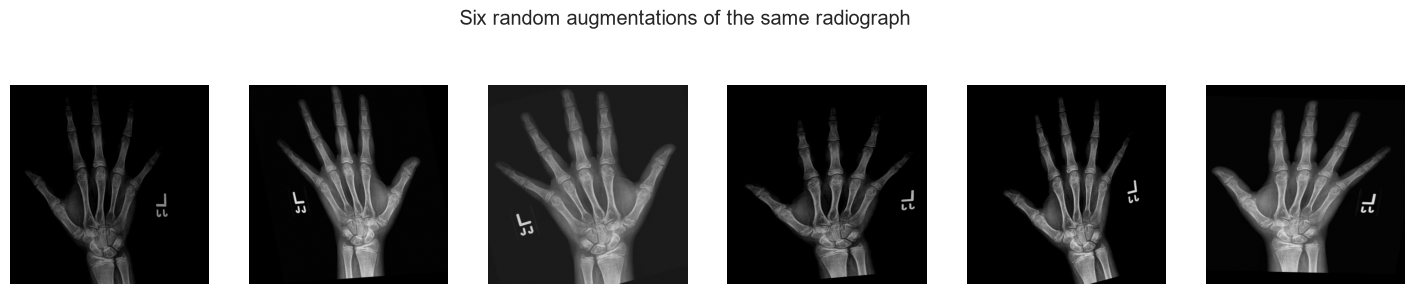

In [13]:
train_tfm = A.Compose([
    A.Affine(scale=(0.85, 1.15), translate_percent=(-0.06, 0.06), rotate=(-20, 20), shear=(-5, 5), p=0.9),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.8),
    A.RandomGamma(gamma_limit=(80, 120), p=0.5),
    A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE),
])
valid_tfm = A.Compose([A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE)])

def make_ds(frame, train):
    target = frame.target.values if "target" in frame else np.zeros(len(frame))
    return BoneAgeDataset(frame.cache_path.values, frame.male.values, target, train_tfm if train else valid_tfm)

def make_loader(frame, train):
    return DataLoader(make_ds(frame, train), batch_size=CFG.BATCH_SIZE if train else CFG.BATCH_SIZE * 2,
                      shuffle=train, num_workers=CFG.NUM_WORKERS, pin_memory=torch.cuda.is_available(),
                      drop_last=train, persistent_workers=CFG.NUM_WORKERS > 0)

ds = make_ds(dev_df.iloc[:1], True)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for a in axes:
    a.imshow(ds[0][0][0].numpy() * NORM_STD + NORM_MEAN, cmap="gray", vmin=0, vmax=1); a.axis("off")
plt.suptitle("Six random augmentations of the same radiograph"); savefig("augmentation.png"); plt.show()

## 8. The model: what the X-ray shows + who the child is

```
X-ray (1×512×512) ─► EfficientNetV2-S ─► 1280 image features ─┐
                                                             ├─► concat ─► MLP ─► bone age
sex (0/1) ─────────► Linear(1→32) + SiLU ─► 32 features ──────┘
```

The same hand can mean a different bone age for a boy and for a girl, so the model has to know the sex. I join it to
the image features **before** the final layers, so the head can apply a different standard to each. The X-rays are
grey, so the backbone reads a single channel (timm folds the pretrained RGB filters into one).


In [14]:
class BoneAgeNet(nn.Module):
    def __init__(self, backbone=CFG.BACKBONE, pretrained=CFG.PRETRAINED, sex_dim=32):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0, in_chans=1)
        n = self.backbone.num_features
        self.sex = nn.Sequential(nn.Linear(1, sex_dim), nn.SiLU())
        self.head = nn.Sequential(nn.Linear(n + sex_dim, 512), nn.SiLU(), nn.Dropout(0.2), nn.Linear(512, 1))

    def forward_from_features(self, fmap, male):
        feats = self.backbone.forward_head(fmap, pre_logits=True)
        return self.head(torch.cat([feats, self.sex(male[:, None])], 1)).squeeze(1)

    def forward(self, x, male):
        return self.forward_from_features(self.backbone.forward_features(x), male)

_m = BoneAgeNet(pretrained=False)
N_PARAMS = sum(p.numel() for p in _m.parameters())
print(f"{CFG.BACKBONE}: {N_PARAMS / 1e6:.1f} M parameters")
with torch.no_grad():
    print("output shape:", _m(torch.randn(2, 1, 224, 224), torch.tensor([0., 1.])).shape)
del _m

tf_efficientnetv2_s.in21k_ft_in1k: 20.8 M parameters
output shape: torch.Size([2])


## 9. Training

Before training starts I run a **GPU preflight**: one real training step at full size. It shows how much memory the
run needs. If the batch doesn't fit (8 GB is tight on a laptop), it halves `BATCH_SIZE` and tries again, so the run
doesn't crash an hour in.

| Choice                                          | Why                                                                                              |
| ----------------------------------------------- | ------------------------------------------------------------------------------------------------ |
| **L1 loss** on the scaled target                | It is the MAE metric itself, and it doesn't overreact to the odd mislabelled X-ray               |
| **AdamW**, head LR 5× backbone LR               | The pretrained backbone needs gentle updates; the new head starts from scratch                   |
| 1 epoch warm-up → **cosine** decay              | A stable start and a smooth finish                                                               |
| **Mixed precision** (fp16) + grad clipping      | Much faster than fp32 (EfficientNetV2 ~40× on my RTX 4060), and stable                           |
| Plain **NCHW** layout (`CHANNELS_LAST = False`) | On my RTX 4060, `channels_last` was ~5× _slower_ (12 vs 62 img/s)                                |
| **EMA** of the weights                          | A smoothed copy of the model, usually a bit more accurate; this copy is what I validate and save |
| **One GPU** on both machines                    | Kaggle's T4 x2 uses one card here, so the laptop and Kaggle run identical code                   |


In [15]:
class EMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.steps = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        d = min(self.decay, (1 + self.steps) / (10 + self.steps))
        for e, m in zip(self.module.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(m.detach(), alpha=1 - d)
            else:
                e.copy_(m)

USE_AMP = CFG.DEVICE == "cuda"
def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

def make_scaler():
    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    return torch.cuda.amp.GradScaler(enabled=USE_AMP)

MEM_FMT = torch.channels_last if CFG.CHANNELS_LAST else torch.contiguous_format
def to_fmt(x):            # images in the chosen memory layout (plain NCHW by default)
    return x.contiguous(memory_format=MEM_FMT)

def to_dev(*ts):
    return [t.to(CFG.DEVICE, non_blocking=True) for t in ts]

def train_one_epoch(model, ema, loader, opt, sched, scaler, loss_fn):
    model.train(); total, n = 0.0, 0
    for x, m, y in loader:
        x, m, y = to_dev(x, m, y)
        x = to_fmt(x)
        with autocast():
            pred = model(x, m)
        loss = loss_fn(pred.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        scaler.step(opt); scaler.update(); sched.step(); ema.update(model)
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.no_grad()
def predict(model, loader, tta=CFG.TTA):
    model.eval(); out = []
    for x, m, _ in loader:
        x, m = to_dev(x, m)
        x = to_fmt(x)
        with autocast():
            p = model(x, m).float()
            if tta:
                p = (p + model(x.flip(3), m).float()) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy() * STD + MEAN      # back to months

def make_scheduler(opt, steps_per_epoch):
    warm, total = CFG.WARMUP_EPOCHS * steps_per_epoch, CFG.EPOCHS * steps_per_epoch
    def f(step):
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

In [16]:
PEAK_GPU_GB = None
if CFG.DEVICE == "cuda":
    while True:
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            m = BoneAgeNet(pretrained=False).to(CFG.DEVICE).to(memory_format=MEM_FMT)
            opt, scaler = torch.optim.AdamW(m.parameters(), 1e-4), make_scaler()
            x = torch.randn(CFG.BATCH_SIZE, 1, CFG.IMG_SIZE, CFG.IMG_SIZE, device=CFG.DEVICE) \
                     .contiguous(memory_format=MEM_FMT)
            male = torch.ones(CFG.BATCH_SIZE, device=CFG.DEVICE)
            with autocast():
                loss = m(x, male).float().abs().mean()
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sync()
            PEAK_GPU_GB = torch.cuda.max_memory_allocated() / 1024 ** 3
            print(f"preflight OK: batch {CFG.BATCH_SIZE} @ {CFG.IMG_SIZE}px, peak GPU memory {PEAK_GPU_GB:.2f} GB "
                  f"of {torch.cuda.get_device_properties(0).total_memory / 1024 ** 3:.1f} GB")
            break
        except torch.cuda.OutOfMemoryError:
            if CFG.BATCH_SIZE <= 4:
                raise
            CFG.BATCH_SIZE //= 2
            print(f"out of memory -> retrying with batch {CFG.BATCH_SIZE}")
        finally:
            m = opt = scaler = x = male = loss = None
            torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
else:
    print("No GPU found: training on CPU will be very slow (use QUICK_DEBUG for a smoke test).")

preflight OK: batch 16 @ 512px, peak GPU memory 6.20 GB of 8.0 GB


In [17]:
def train_fold(fold):
    seed_everything(CFG.SEED + fold)
    tr, va = dev_df[dev_df.fold != fold], dev_df[dev_df.fold == fold]
    tl, vl = make_loader(tr, True), make_loader(va, False)

    model = BoneAgeNet().to(CFG.DEVICE).to(memory_format=MEM_FMT)
    ema = EMA(model, CFG.EMA_DECAY)
    opt = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": CFG.LR},
        {"params": list(model.sex.parameters()) + list(model.head.parameters()), "lr": CFG.LR * CFG.HEAD_LR_MULT},
    ], weight_decay=CFG.WEIGHT_DECAY)
    sched, scaler = make_scheduler(opt, len(tl)), make_scaler()
    loss_fn = nn.L1Loss() if CFG.LOSS == "l1" else nn.SmoothL1Loss(beta=0.1)

    best, best_ep, hist = 1e9, 0, []
    ckpt = os.path.join(MODEL_DIR, f"fold{fold}.pt")
    for ep in range(CFG.EPOCHS):
        sync(); t0 = time.time()
        tr_loss = train_one_epoch(model, ema, tl, opt, sched, scaler, loss_fn)
        sync(); t1 = time.time()
        va_pred = predict(ema.module, vl, tta=False)
        sync(); t2 = time.time()
        va_mae = mae(va_pred, va.boneage.values)
        hist.append({"fold": fold, "epoch": ep + 1, "train_l1_months": tr_loss * STD, "val_mae": va_mae,
                     "train_s": t1 - t0, "val_s": t2 - t1, "train_img_per_s": len(tl) * CFG.BATCH_SIZE / (t1 - t0)})
        flag = ""
        if va_mae < best:
            best, best_ep, flag = va_mae, ep + 1, "  *"
            torch.save(ema.module.state_dict(), ckpt)
        print(f"fold {fold} ep {ep + 1:02d}/{CFG.EPOCHS} | train L1 {tr_loss * STD:5.2f} mo | "
              f"val MAE {va_mae:5.2f} mo | {t1 - t0:4.0f}s train + {t2 - t1:3.0f}s val{flag}")
    print(f"fold {fold}: best val MAE {best:.3f} months at epoch {best_ep}")
    del model, ema, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return hist, best, best_ep

t0 = time.time()
history, fold_best, fold_best_ep = [], {}, {}
for f in CFG.TRAIN_FOLDS:
    h, b, e = train_fold(f)
    history += h; fold_best[f] = b; fold_best_ep[f] = e
TIMES["train_s"] = time.time() - t0
if torch.cuda.is_available():
    PEAK_GPU_GB = max(PEAK_GPU_GB or 0, torch.cuda.max_memory_allocated() / 1024 ** 3)
hist_df = pd.DataFrame(history)
hist_df.to_csv(os.path.join(WORK_DIR, "history.csv"), index=False)
print(f"training: {TIMES['train_s'] / 60:.1f} min for {len(CFG.TRAIN_FOLDS)} fold(s)")

fold 0 ep 01/20 | train L1 16.26 mo | val MAE  7.83 mo |  188s train +  81s val  *
fold 0 ep 02/20 | train L1  9.85 mo | val MAE  7.10 mo |  168s train +  13s val  *
fold 0 ep 03/20 | train L1  8.68 mo | val MAE  6.71 mo |  184s train +  13s val  *
fold 0 ep 04/20 | train L1  8.40 mo | val MAE  6.58 mo |  184s train +  12s val  *
fold 0 ep 05/20 | train L1  8.07 mo | val MAE  6.52 mo |  159s train +  12s val  *
fold 0 ep 06/20 | train L1  7.66 mo | val MAE  6.49 mo |  156s train +  12s val  *
fold 0 ep 07/20 | train L1  7.60 mo | val MAE  6.49 mo |  152s train +  12s val  *
fold 0 ep 08/20 | train L1  7.36 mo | val MAE  6.44 mo |  168s train +  12s val  *
fold 0 ep 09/20 | train L1  7.17 mo | val MAE  6.36 mo |  173s train +  12s val  *
fold 0 ep 10/20 | train L1  6.99 mo | val MAE  6.32 mo |  157s train +  12s val  *
fold 0 ep 11/20 | train L1  6.66 mo | val MAE  6.29 mo |  161s train +  12s val  *
fold 0 ep 12/20 | train L1  6.44 mo | val MAE  6.28 mo |  157s train +  12s val  *
fold

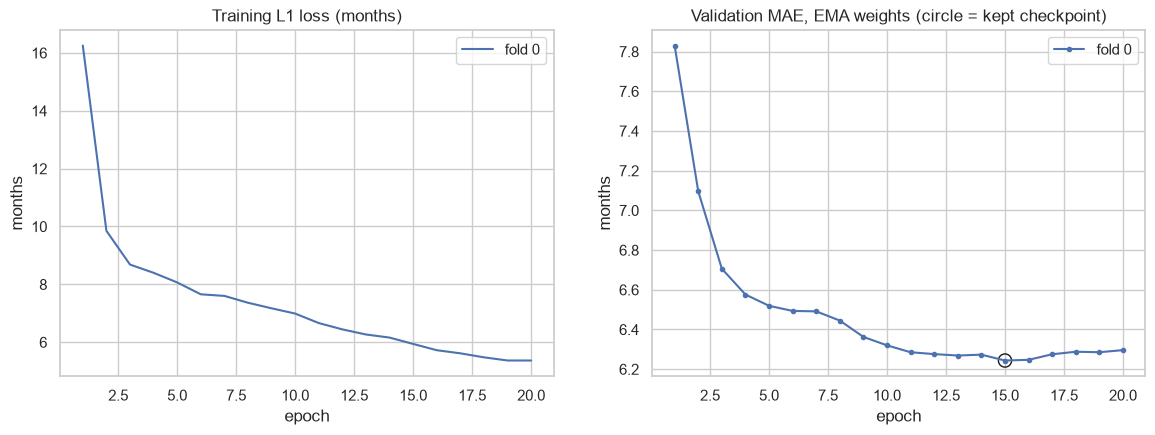

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for f, g in hist_df.groupby("fold"):
    ax[0].plot(g.epoch, g.train_l1_months, label=f"fold {f}")
    ax[1].plot(g.epoch, g.val_mae, marker="o", ms=3, label=f"fold {f}")
    ax[1].scatter([fold_best_ep[f]], [fold_best[f]], s=90, facecolors="none", edgecolors="k")
ax[0].set(title="Training L1 loss (months)", xlabel="epoch", ylabel="months")
ax[1].set(title="Validation MAE, EMA weights (circle = kept checkpoint)", xlabel="epoch", ylabel="months")
for a in ax: a.legend()
savefig("training_curves.png"); plt.show()

## 10. The moment of truth: the hold-out set

Now the locked-away 1,425 images come out. Each trained model predicts every image twice (as-is and mirrored) and
averages the two. With more than one fold, the folds are averaged as well. All results are in months, for boys and
girls separately, next to the two baselines and to published results.


In [19]:
def load_model(fold):
    m = BoneAgeNet(pretrained=False).to(CFG.DEVICE).to(memory_format=MEM_FMT)
    m.load_state_dict(torch.load(os.path.join(MODEL_DIR, f"fold{fold}.pt"), map_location=CFG.DEVICE))
    return m.eval()

hold_loader = make_loader(hold_df, False)
test_loader = make_loader(test_df, False) if test_df is not None else None
hold_preds, test_preds = {}, {}
infer_s = 0.0
for f in CFG.TRAIN_FOLDS:
    m = load_model(f)
    sync(); t0 = time.time()
    hold_preds[f] = predict(m, hold_loader)
    sync(); infer_s += time.time() - t0
    if test_loader is not None:
        test_preds[f] = predict(m, test_loader)
    del m
TIMES["holdout_infer_s"] = infer_s
TIMES["infer_img_per_s"] = len(hold_df) * len(CFG.TRAIN_FOLDS) * (2 if CFG.TTA else 1) / infer_s

hold_df["pred"] = np.clip(np.mean(list(hold_preds.values()), 0), 0, 240)
y, p = hold_df.boneage.values, hold_df.pred.values
err = p - y
SUMMARY = {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
           "R2": float(1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum()), "bias": float(err.mean()),
           "within_6mo": float((np.abs(err) <= 6).mean()), "within_12mo": float((np.abs(err) <= 12).mean())}

rows = dict(baselines)
for f, pr in hold_preds.items():
    rows[f"CNN fold {f} (TTA)"] = report(pr, hold_df)
ENS_NAME = f"CNN ensemble x{len(hold_preds)} (TTA)"
rows[ENS_NAME] = report(p, hold_df)
results = pd.DataFrame(rows).T
results["vs mean baseline"] = (1 - results.MAE / results.loc["Mean predictor", "MAE"]).map("{:.0%}".format)
print(f"Hold-out n={len(hold_df)} | MAE {SUMMARY['MAE']:.2f} mo | RMSE {SUMMARY['RMSE']:.2f} mo | "
      f"R² {SUMMARY['R2']:.4f} | bias {SUMMARY['bias']:+.2f} mo")
print(f"within ±6 mo: {SUMMARY['within_6mo']:.1%} | within ±12 mo: {SUMMARY['within_12mo']:.1%}")
results.round(2)

Hold-out n=1425 | MAE 6.11 mo | RMSE 8.20 mo | R² 0.9598 | bias -0.05 mo
within ±6 mo: 59.9% | within ±12 mo: 87.6%


,MAE,MAE_boys,MAE_girls,vs mean baseline
Mean predictor,33.34,35.92,30.30,0%
Sex-specific mean,32.00,33.57,30.14,4%
CNN fold 0 (TTA),6.11,5.96,6.28,82%
CNN ensemble x1 (TTA),6.11,5.96,6.28,82%


,MAE (months),Note
RSNA winner,4.2,"RSNA 2017 challenge winner, official 200-case ..."
Radiologists,4.8 – 7.0,Individual radiologists vs. reference panel (H...
Ours,6.11,This notebook (local-geforce-rtx-4060-laptop-g...


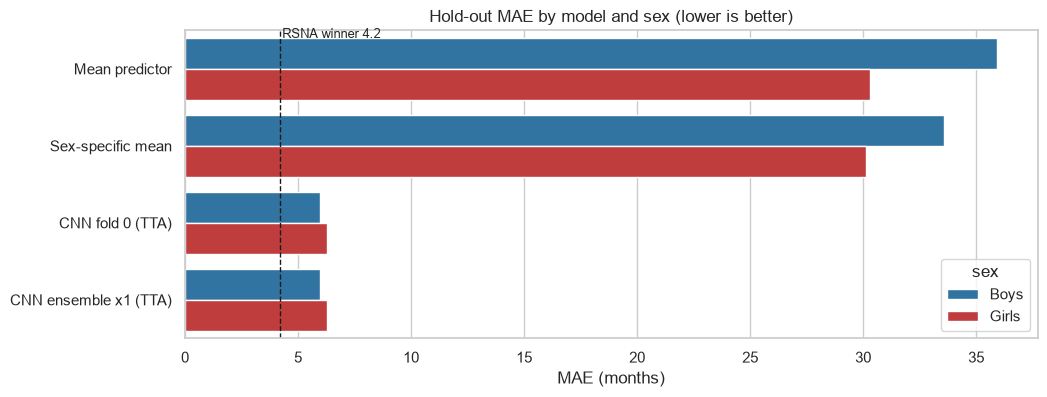

In [20]:
reference = pd.DataFrame({
    "MAE (months)": ["4.2", "4.8 – 7.0", f"{SUMMARY['MAE']:.2f}"],
    "Note": ["RSNA 2017 challenge winner, official 200-case test set",
             "Individual radiologists vs. reference panel (Halabi et al., 2019)",
             f"This notebook ({CFG.RUN_TAG}), {len(hold_preds)}-model ensemble, stratified hold-out (n={len(hold_df)})"],
}, index=["RSNA winner", "Radiologists", "Ours"])
display(reference)

plot_df = results[["MAE_boys", "MAE_girls"]].rename(columns={"MAE_boys": "Boys", "MAE_girls": "Girls"}) \
                 .reset_index().melt(id_vars="index", var_name="sex", value_name="MAE")
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(plot_df, y="index", x="MAE", hue="sex", palette=PAL, ax=ax)
ax.axvline(4.2, color="k", ls="--", lw=1); ax.text(4.3, -0.4, "RSNA winner 4.2", fontsize=9)
ax.set(title="Hold-out MAE by model and sex (lower is better)", xlabel="MAE (months)", ylabel="")
savefig("mae_by_model.png"); plt.show()

In [21]:
band = hold_df.assign(abs_err=np.abs(err)).groupby(["age_band", "sex"], observed=True).abs_err \
              .agg(["mean", "count"]).unstack("sex").round(2)
band

mean        count      
sex             Boys  Girls  Boys Girls
age_band                               
(-0.001, 24.0]  7.41   5.48    11     8
(24.0, 48.0]    6.09   5.14    24    22
(48.0, 72.0]    6.33   6.19    60    55
(72.0, 96.0]    8.39   6.96    66   122
(96.0, 120.0]   8.39   7.24    88   141
(120.0, 144.0]  7.55   5.49   120   167
(144.0, 168.0]  4.25   6.00   306    99
(168.0, 192.0]  5.06   5.02    63    34
(192.0, 240.0]  5.18  10.05    34     5

## 11. Where does it go wrong?

One MAE number hides a lot, so here are three views of the errors:

- **Predicted vs. true:** points on the dashed line are perfect predictions.
- **Bland–Altman:** does the model run systematically high or low (bias), and how wide is the spread?
- **MAE by age band:** infants and late teenagers are hard even for radiologists. Let's see if the same is true here.


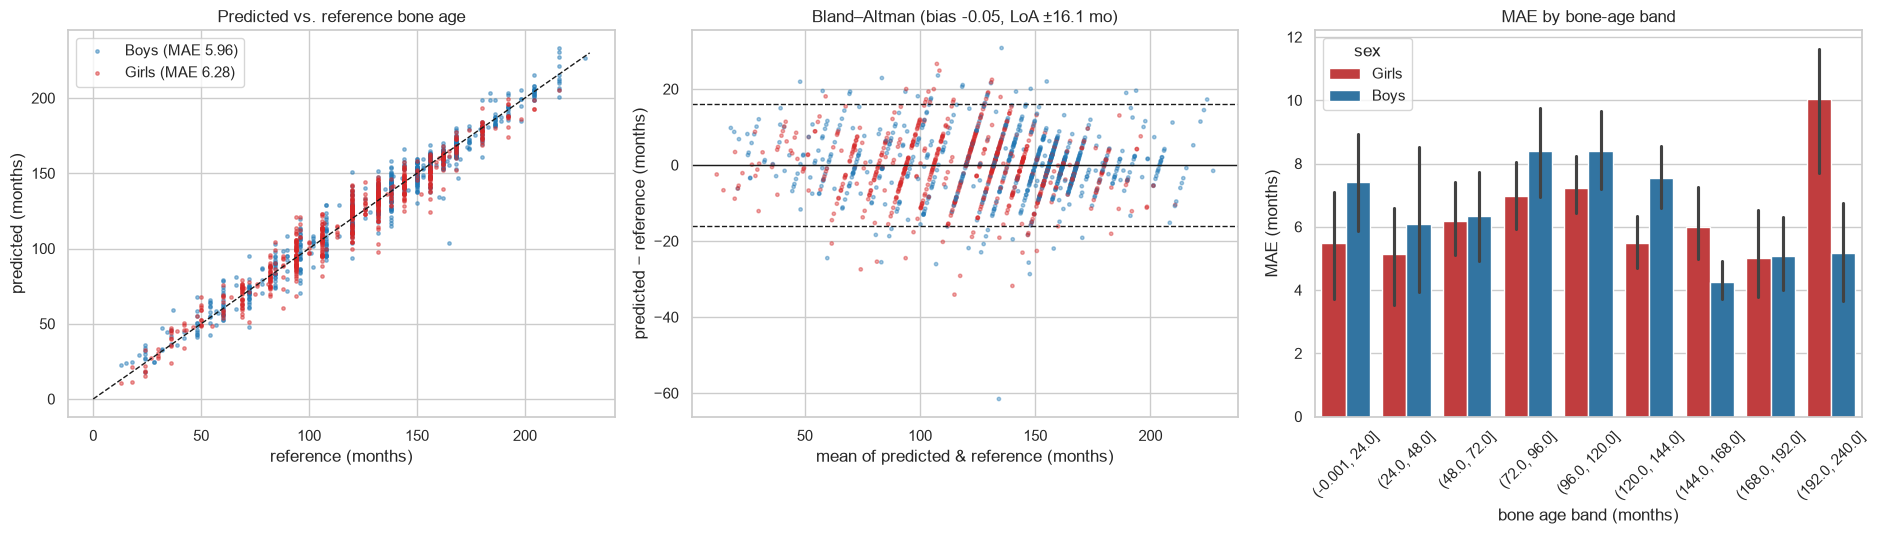

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for s, g in hold_df.groupby("sex"):
    ax[0].scatter(g.boneage, g.pred, s=6, alpha=.45, c=PAL[s], label=f"{s} (MAE {mae(g.pred, g.boneage):.2f})")
ax[0].plot([0, 230], [0, 230], "k--", lw=1)
ax[0].set(title="Predicted vs. reference bone age", xlabel="reference (months)", ylabel="predicted (months)")
ax[0].legend()

mean_pair = (hold_df.pred + hold_df.boneage) / 2
ax[1].scatter(mean_pair, err, s=6, alpha=.4, c=hold_df.sex.map(PAL))
loa = 1.96 * err.std()
for v, ls in [(err.mean(), "-"), (err.mean() + loa, "--"), (err.mean() - loa, "--")]:
    ax[1].axhline(v, color="k", ls=ls, lw=1)
ax[1].set(title=f"Bland–Altman (bias {err.mean():+.2f}, LoA ±{loa:.1f} mo)",
          xlabel="mean of predicted & reference (months)", ylabel="predicted − reference (months)")

b = hold_df.assign(abs_err=np.abs(err))
sns.barplot(b, x="age_band", y="abs_err", hue="sex", palette=PAL, ax=ax[2], errorbar=("ci", 95))
ax[2].set(title="MAE by bone-age band", xlabel="bone age band (months)", ylabel="MAE (months)")
ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("error_analysis.png"); plt.show()

### Grad-CAM: what is the model looking at?

A good score could still come from a shortcut, like a ruler or a hospital label in the corner. Grad-CAM shows which
regions drove each prediction. I'd like to see heat on the **growth plates** of the fingers and on the **wrist bones**,
the same places a radiologist reads.


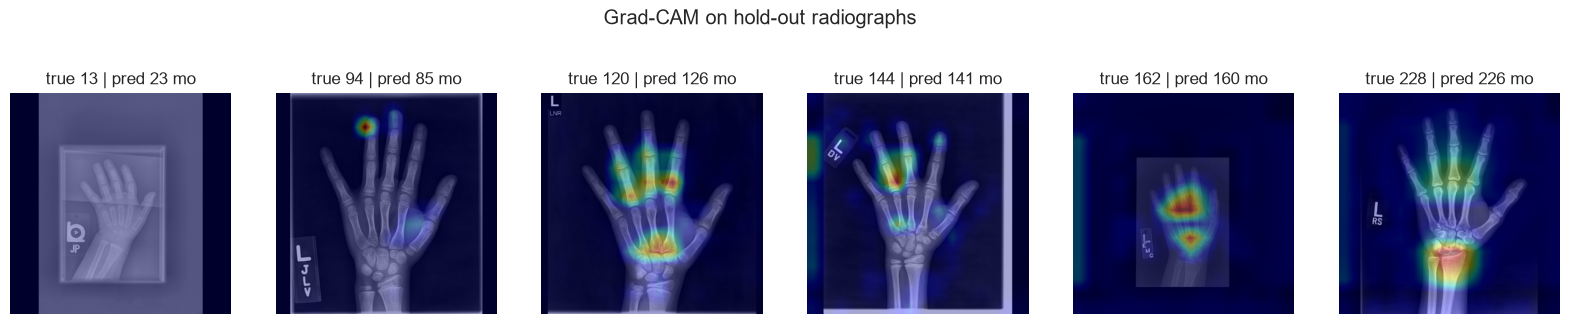

In [23]:
def grad_cam(model, x, male):
    model.eval(); model.zero_grad(set_to_none=True)
    fmap = model.backbone.forward_features(x)
    fmap.retain_grad()
    model.forward_from_features(fmap, male).sum().backward()
    w = fmap.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * fmap).sum(1))
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-6)
    return cam.detach().cpu().numpy()

cam_model = load_model(CFG.TRAIN_FOLDS[0]).float()
sample = hold_df.sort_values("boneage").iloc[np.linspace(0, len(hold_df) - 1, 6).astype(int)]
ds = make_ds(sample, False)
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for i, a in enumerate(axes):
    x, m, _ = ds[i]
    cam = grad_cam(cam_model, x[None].to(CFG.DEVICE), m[None].to(CFG.DEVICE))[0]
    cam = cv2.resize(cam, (CFG.IMG_SIZE, CFG.IMG_SIZE))
    a.imshow(x[0].numpy() * NORM_STD + NORM_MEAN, cmap="gray"); a.imshow(cam, cmap="jet", alpha=.35); a.axis("off")
    r = sample.iloc[i]
    a.set_title(f"true {r.boneage:.0f} | pred {r.pred:.0f} mo")
plt.suptitle("Grad-CAM on hold-out radiographs"); savefig("gradcam.png"); plt.show()
del cam_model

## 12. Test predictions, trying one image, and saving the run

The Kaggle test images have no public labels, so I only save predictions for them. `predict_bone_age()` runs the
whole pipeline on any single X-ray. Last, the run record: hardware, software, timings and every score go into
`work/runs/run_<tag>.json`, which is what makes the laptop-vs-Kaggle comparison possible.


In [24]:
if test_preds:
    sub = test_df[["id"]].rename(columns={"id": "Case ID"})
    sub["predicted_boneage_months"] = np.clip(np.mean(list(test_preds.values()), 0), 0, 240).round(1)
    sub.to_csv(os.path.join(WORK_DIR, "test_predictions.csv"), index=False)
    display(sub.head())

_models = None
def predict_bone_age(path, male):
    # Predict bone age (months) for one radiograph path; male = True/False.
    global _models
    if _models is None:
        _models = [load_model(f) for f in CFG.TRAIN_FOLDS]
    img = valid_tfm(image=load_hand(path, CFG.CACHE_SIZE, CFG.USE_CLAHE))["image"]
    x = to_tensor(img)[None].to(CFG.DEVICE)
    m = torch.tensor([float(male)], device=CFG.DEVICE)
    with torch.no_grad(), autocast():
        preds = [((mdl(x, m) + mdl(x.flip(3), m)) / 2).float().item() for mdl in _models]
    return float(np.mean(preds) * STD + MEAN)

r = hold_df.iloc[0]
print(f"id {r.id}: reference {r.boneage:.0f} mo, predicted {predict_bone_age(r.path, r.male):.1f} mo")

,Case ID,predicted_boneage_months
0,4360,170.4
1,4361,167.8
2,4362,65.0
3,4363,149.1
4,4364,140.5


id 5161: reference 132 mo, predicted 133.6 mo


In [25]:
def _ver(mod):
    try:
        return __import__(mod).__version__
    except Exception:
        return None

def ram_gb():
    try:
        import psutil
        return round(psutil.virtual_memory().total / 1024 ** 3, 1)
    except Exception:
        return None

TIMES["total_s"] = time.time() - T_START
RUN = {
    "tag": CFG.RUN_TAG,
    "platform": "kaggle" if ON_KAGGLE else "local",
    "finished": time.strftime("%Y-%m-%d %H:%M"),
    "hardware": {
        "gpu": gpu_name,
        "gpu_mem_gb": round(torch.cuda.get_device_properties(0).total_memory / 1024 ** 3, 1) if torch.cuda.is_available() else None,
        "gpu_count": torch.cuda.device_count(), "cpu_threads": os.cpu_count(), "ram_gb": ram_gb(),
        "os": f"{platform.system()} {platform.release()}",
    },
    "software": {"python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
                 "cudnn": torch.backends.cudnn.version(), "timm": timm.__version__,
                 "albumentations": A.__version__, "opencv": cv2.__version__},
    "config": {k: getattr(CFG, k) for k in ["SEED", "BACKBONE", "IMG_SIZE", "CACHE_SIZE", "USE_CLAHE", "BATCH_SIZE",
               "EPOCHS", "LR", "HEAD_LR_MULT", "WEIGHT_DECAY", "EMA_DECAY", "LOSS", "N_FOLDS", "TRAIN_FOLDS",
               "TTA", "NUM_WORKERS", "QUICK_DEBUG"]},
    "data": {"n_labelled": len(df), "n_dev": len(dev_df), "n_holdout": len(hold_df),
             "n_test": 0 if test_df is None else len(test_df), "target_mean": MEAN, "target_std": STD},
    "model": {"params_m": round(N_PARAMS / 1e6, 2)},
    "timing": {**{k: round(v, 2) for k, v in TIMES.items()},
               "epoch_train_s_mean": round(hist_df.train_s.mean(), 2),
               "epoch_val_s_mean": round(hist_df.val_s.mean(), 2),
               "train_img_per_s": round(hist_df.train_img_per_s.median(), 1)},
    "memory": {"peak_gpu_gb": None if PEAK_GPU_GB is None else round(PEAK_GPU_GB, 2)},
    "results": {
        "holdout": {k: {kk: round(vv, 3) for kk, vv in v.items()} for k, v in rows.items()},
        "ensemble_name": ENS_NAME,
        "summary": {k: round(v, 4) for k, v in SUMMARY.items()},
        "fold_val_mae": {str(k): round(v, 3) for k, v in fold_best.items()},
        "fold_best_epoch": {str(k): v for k, v in fold_best_ep.items()},
        "age_bands": [{"band": f"{max(0, int(bnd.left))}–{int(bnd.right)}", "sex": s,
                       "mae": round(float(g.mean()), 3), "n": int(len(g))}
                      for (bnd, s), g in hold_df.assign(e=np.abs(err)).groupby(["age_band", "sex"], observed=True).e],
    },
}
with open(os.path.join(RUNS_DIR, f"run_{CFG.RUN_TAG}.json"), "w") as fh:
    json.dump(RUN, fh, indent=2, default=str)
hold_df[["id", "boneage", "male", "pred"]].to_csv(os.path.join(RUNS_DIR, f"holdout_pred_{CFG.RUN_TAG}.csv"), index=False)
try:
    results.round(2).to_markdown(open(os.path.join(WORK_DIR, "results_table.md"), "w"))   # needs `tabulate`
except ImportError:
    pass
print(f"run record -> {os.path.join(RUNS_DIR, f'run_{CFG.RUN_TAG}.json')}  | total {TIMES['total_s'] / 60:.1f} min")

run record -> d:\ML\Bone Age From Hand X-Rays\Notebook\work\runs\run_local-geforce-rtx-4060-laptop-gpu.json  | total 65.3 min


## 13. Laptop RTX 4060 vs. Kaggle GPU

I ran the same notebook on two machines and wanted a fair answer to two questions: **how much faster is one than the
other**, and **do they reach the same accuracy?** Both runs use the same split and seed, so they score the _same_
1,425 hold-out images and their predictions can be compared image by image.

**How to compare**

1. Run on Kaggle with **Save Version → Save & Run All**. From the version's **Output** tab, download
   `runs/run_kaggle-*.json` and `runs/holdout_pred_kaggle-*.csv`.
2. Unzip the Kaggle output next to the `Notebook/` folder (for example `Bone-Age-RSNA-Azmi-Kaggle_Outputs/`), or copy the two files into `Notebook/work/runs/`. Both places are found automatically. To only redo the comparison,
   run sections 1 and 13.
3. When run locally, the last cell writes the comparison tables straight into the project `README.md`.


In [26]:
# This machine's runs first, then runs copied from elsewhere: any "<folder>/runs/" next to the Notebook folder
# (e.g. the unzipped Kaggle output "Bone-Age-RSNA-Azmi-Kaggle_Outputs/runs/") or an attached Kaggle input.
run_files = list(dict.fromkeys(
    sorted(glob.glob(os.path.join(RUNS_DIR, "run_*.json"))) +
    sorted(glob.glob(os.path.join(NOTEBOOK_DIR, "..", "*", "runs", "run_*.json"))) +
    sorted(glob.glob(os.path.join(NOTEBOOK_DIR, "..", "*", "*", "runs", "run_*.json"))) +
    sorted(glob.glob("/kaggle/input/**/run_*.json", recursive=True))))
runs = {}
for fpath in run_files:
    with open(fpath) as fh:
        rr = json.load(fh)
    runs.setdefault(rr["tag"], (rr, os.path.join(os.path.dirname(fpath), f"holdout_pred_{rr['tag']}.csv")))
print("runs found:", list(runs))

def row(rr):
    t, h, s, res = rr["timing"], rr["hardware"], rr["software"], rr["results"]
    ens = res["holdout"][res["ensemble_name"]]
    return {"GPU": h["gpu"], "VRAM (GB)": h["gpu_mem_gb"], "CPU threads": h["cpu_threads"],
            "torch / CUDA": f"{s['torch']} / {s['cuda']}", "batch": rr["config"]["BATCH_SIZE"],
            "peak GPU mem (GB)": rr["memory"]["peak_gpu_gb"],
            "cache (min)": round(t.get("cache_s", 0) / 60, 1),
            "train epoch (s)": t["epoch_train_s_mean"], "train img/s": t["train_img_per_s"],
            "inference img/s": round(t.get("infer_img_per_s", 0), 1),
            "training (min)": round(t["train_s"] / 60, 1), "whole notebook (min)": round(t["total_s"] / 60, 1),
            "hold-out MAE": round(ens["MAE"], 2), "MAE boys": round(ens["MAE_boys"], 2),
            "MAE girls": round(ens["MAE_girls"], 2), "best epoch": ", ".join(map(str, res["fold_best_epoch"].values()))}

cmp_df = pd.DataFrame({tag: row(rr) for tag, (rr, _) in runs.items()})
display(cmp_df)

cfg_keys = ["BACKBONE", "IMG_SIZE", "EPOCHS", "TRAIN_FOLDS", "SEED", "BATCH_SIZE"]
cfgs = pd.DataFrame({tag: {k: str(rr["config"][k]) for k in cfg_keys} for tag, (rr, _) in runs.items()})
diff = cfgs[cfgs.nunique(axis=1) > 1]
if len(runs) > 1 and len(diff):
    print("⚠ the runs differ in these settings, so timings/scores are not a like-for-like comparison:")
    display(diff)

if len(runs) >= 2:
    tags = list(runs)
    fig, ax = plt.subplots(1, 4, figsize=(20, 4))
    colors = sns.color_palette("Set2", len(tags))
    for a, col, title in zip(ax, ["train img/s", "train epoch (s)", "whole notebook (min)", "hold-out MAE"],
                             ["Training throughput (img/s, higher = faster)", "Seconds per training epoch",
                              "Whole notebook (minutes)", "Hold-out MAE (months)"]):
        vals = [float(cmp_df.loc[col, t]) for t in tags]
        a.bar(range(len(tags)), vals, color=colors); a.set_title(title, fontsize=10)
        a.set_xticks(range(len(tags))); a.set_xticklabels(tags, rotation=15, ha="right", fontsize=8)
        for i, v in enumerate(vals):
            a.text(i, v, f"{v:.2f}" if v < 100 else f"{v:.0f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout(); savefig("hardware_comparison.png"); plt.show()

    preds = {t: pd.read_csv(pth).set_index("id").pred for t, (_, pth) in runs.items() if os.path.exists(pth)}
    if len(preds) >= 2:
        a_t, b_t = list(preds)[:2]
        j = pd.concat([preds[a_t], preds[b_t]], axis=1, keys=[a_t, b_t]).dropna()
        d = (j[a_t] - j[b_t]).abs()
        print(f"Agreement on the same {len(j)} hold-out images: mean |Δ| {d.mean():.2f} mo, "
              f"max |Δ| {d.max():.2f} mo, Pearson r {j[a_t].corr(j[b_t]):.4f}")
else:
    print("Only one run so far. Run the notebook on the other machine and copy its runs/ files here to compare.")

runs found: ['local-geforce-rtx-4060-laptop-gpu']


,local-geforce-rtx-4060-laptop-gpu
GPU,NVIDIA GeForce RTX 4060 Laptop GPU
VRAM (GB),8.0
CPU threads,16
torch / CUDA,2.11.0+cu128 / 12.8
batch,16
peak GPU mem (GB),6.48
cache (min),0.0
train epoch (s),165.74
train img/s,56.0
inference img/s,49.1


Only one run so far. Run the notebook on the other machine and copy its runs/ files here to compare.


In [27]:
# Write the results into ../README.md between the <!-- AUTO:... --> markers (local runs only).
README = os.path.join(NOTEBOOK_DIR, "..", "README.md")

def md_table(frame):
    cols = [""] + [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, r in frame.iterrows():
        lines.append("| " + " | ".join([f"**{idx}**"] + ["" if pd.isna(v) else str(v) for v in r.values]) + " |")
    return "\n".join(lines)

def fill(text, key, body):
    pat = re.compile(rf"(<!-- AUTO:{key}:START -->)(.*?)(<!-- AUTO:{key}:END -->)", re.S)
    return pat.sub(lambda m: f"{m.group(1)}\n{body}\n{m.group(3)}", text)

if not ON_KAGGLE and os.path.exists(README) and runs:
    best_tag = min(runs, key=lambda t: runs[t][0]["results"]["summary"]["MAE"])
    best = runs[best_tag][0]
    res = best["results"]
    hold = pd.DataFrame(res["holdout"]).T[["MAE", "MAE_boys", "MAE_girls"]].round(2)
    hold.columns = ["MAE (months)", "Boys", "Girls"]
    hold["vs. mean baseline"] = (hold["MAE (months)"] / hold.loc["Mean predictor", "MAE (months)"] - 1) \
                                    .map("{:+.0%}".format).str.replace("-", "−", regex=False)
    hold.loc["Mean predictor", "vs. mean baseline"] = "—"
    s = res["summary"]
    headline = (f"| Hold-out MAE ↓ | Boys | Girls | vs. mean baseline | Within ±12 mo | R² | Best GPU run |\n"
                f"|:---:|:---:|:---:|:---:|:---:|:---:|:---:|\n"
                f"| **{s['MAE']:.2f} mo** | {res['holdout'][res['ensemble_name']]['MAE_boys']:.2f} | "
                f"{res['holdout'][res['ensemble_name']]['MAE_girls']:.2f} | "
                f"{s['MAE'] / res['holdout']['Mean predictor']['MAE'] - 1:+.0%} | {s['within_12mo']:.0%} | "
                f"{s['R2']:.3f} | {best['hardware']['gpu']} |")
    bdf = pd.DataFrame(res["age_bands"])
    bdf["band"] = pd.Categorical(bdf.band + " mo", categories=list(dict.fromkeys(bdf.band + " mo")), ordered=True)
    bands = bdf.pivot_table(index="band", columns="sex", values="mae", observed=True).round(2)
    n = bdf.pivot_table(index="band", columns="sex", values="n", observed=True, aggfunc="sum")
    bands = bands.astype(str) + " (n=" + n.astype("Int64").astype(str) + ")"
    bands = bands.replace(r".*nan.*|.*<NA>.*", "–", regex=True)
    bands.index.name = None
    hw = md_table(cmp_df.astype(object))
    agree = ""
    if len(runs) >= 2 and len(preds) >= 2:
        agree = (f"\n\nOn the same {len(j)} hold-out images the two runs' predictions differ by "
                 f"**{d.mean():.2f} months** on average (max {d.max():.2f}), Pearson r = {j[a_t].corr(j[b_t]):.4f}.")
    text = open(README, encoding="utf-8").read()
    text = fill(text, "HEADLINE", headline)
    text = fill(text, "RESULTS", md_table(hold) + f"\n\n<sub>Run `{best_tag}`, finished {best['finished']}. "
                                 f"Source: `Notebook/work/runs/run_{best_tag}.json`.</sub>")
    text = fill(text, "BANDS", md_table(bands))
    text = fill(text, "HARDWARE", hw + agree + f"\n\n<sub>Generated from {len(runs)} run file(s) in `Notebook/work/runs/`.</sub>")
    open(README, "w", encoding="utf-8").write(text)
    print("README.md updated with", len(runs), "run(s)")
else:
    print("README not updated (runs on Kaggle, no ../README.md, or no run files yet).")

README.md updated with 1 run(s)


## 14. What I learned and what's next

- The CNN is measured on X-rays it never saw, in months, for boys and girls separately, against two baselines that
  ignore the image, and on two different GPUs with the same split and seed.
- If you want a lower MAE, here's what I would try next, roughly in order of payoff:
  1. Train all 5 folds (`TRAIN_FOLDS = [0, 1, 2, 3, 4]`) and ensemble them.
  2. Higher resolution (`IMG_SIZE = 640`, `CACHE_SIZE = 704`) with a larger backbone (EfficientNetV2-M, ConvNeXt-S).
  3. Longer training (30–40 epochs) and a second backbone family in the ensemble.
  4. Hand detection / cropping before resizing; region-of-interest branches for carpal bones and phalanges.
- **Caveat:** the RSNA winner's 4.2 months was measured on the official 200-image test set with a multi-reader
  reference; our hold-out comes from the training distribution, so the numbers are close in spirit but not directly
  comparable.
- **Not a medical device.** Research and educational project; not validated for clinical use.
